# Applying Connectome Spectrum Electromagnetic Tomography (CSET) on individual data

CSET solves the following optimization problem: 
$$\hat {\mathbf s}^* = \underset{\hat{\mathbf s}}{\text{argmin}} \lVert \mathbf{LU}\hat{\mathbf s}-\mathbf{y} \rVert_2^2 + \lambda \lVert \hat{\mathbf s}\rVert_1$$
$$ \mathbf s^* = \mathbf U \hat{\mathbf s}$$

where
- $\mathbf{s}^* \in \mathbb{R}^n$ are the reconstructed dipole strengths
- $\hat{\mathbf{s}}^* \in \mathbb{R}^n$ is the reconstructed connectome spectrum.
- $\mathbf{y} \in \mathbb{R}^m$ are the EEG measurements.
- $\mathbf L \in \mathbb{R}^{m\times n}$ is the lead field matrix.
- $\mathbf U \in \mathbb{R}^{n \times n}$ is the inverse graph Fourier transform
- $\lambda \in \mathbb{R}$ is the regularizer parameter.

Regularizing with $\lVert \hat {\mathbf s}\rVert_1$ imposes the connectome spectrum to be sparse.

# Batch Wise Run
Run the code for all subjects of a given dataset.

## 📦 Imports

In [1]:
import mindmap as mm
from pathlib import Path

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `eeg`: Preprocessed EEG
- `fwd`: Forward operator
- `cst`: Connectome spectrum transform

🛠️ <font color=violet>**Configuration**</font>:
- `fconfig`: Configuration file.

🛠️ <font color=violet>**EEG**</font>:
- `win_size`: Time window size around EEG peak in [s]

🛠️ <font color=violet>**CSET**</font>:
- `lam`: connectome spectrum sparseness parameter.
- `dw`: depth weighting parameter

🛠️ <font color=violet>**Other options**</font>:
- `overwrite`: Whether to overwrite existing files.

In [9]:
################# Parameters #################
# configuration
fconfig = "../configurations/simf.yml"

# EEG
win_size = 0.1

# CSET
lam = 0.1
dw = 1/2

# other options
overwrite = True
##############################################

# config
config   = mm.io.read_config("../configurations/spike.yml")
subjects = config["SUBS"]
samples  = config["SAMP"]
mm_dir   = Path(config["MM_DIR"])

# options
overwrite = True


# file naming
fstc = lambda sub, samp: mm_dir/sub/"inv"/f"{sub}-{samp}_cset-{lam}"

## ♾️ Loop

In [10]:
for sub in subjects:
    for samp in samples:

        # check file existence
        fname = fstc(sub, samp)
        if fname.exists() and not overwrite:
            print(f"\033[93mCSET solution already exists for subject {sub} with lam={lam}\033[0m")
        if not fname.parent.exists():
            fname.mkdir(parents=True)

        try: 
            data = mm.io.read_dataset(sub, "eeg", "fwd", "cst", sample=samp)
            stc  = mm.cset(data["eeg"], data["fwd"], data["cst"], lam, dw, win_size, sub)
        except Exception as e:
            print(f"\033[91mFailed to compute CSET solution for subject '{sub}', sample '{samp}' due to {e}\033[0m")
            continue
            
        # save
        stc.save(fname, overwrite=True, verbose="warning")
        print(f"\033[92mSuccessfully computed CSET inverse solution for subject '{sub}', sample '{samp}'\033[0m")

Preprocessed EEG not found, reading raw instead.
Failed to compute CSET solution for subject 'sub-pat01', sample 'spike' due to File does not exist: "/media/nino/DATA/SPIKE/derivatives/mindmap/sub-pat01/fwd/sub-pat01_fwd.fif"
DATA SUMMARY
Dataset: spike
Subject: sub-pat02
Retrieved objects:
- cst
- fwd
- eeg
Missing objects:
Successfully computed CSET inverse solution for subject 'sub-pat02', sample 'spike'
DATA SUMMARY
Dataset: spike
Subject: sub-pat03
Retrieved objects:
- cst
- fwd
- eeg
Missing objects:
Successfully computed CSET inverse solution for subject 'sub-pat03', sample 'spike'
DATA SUMMARY
Dataset: spike
Subject: sub-pat04
Retrieved objects:
- cst
- fwd
- eeg
Missing objects:
Successfully computed CSET inverse solution for subject 'sub-pat04', sample 'spike'
DATA SUMMARY
Dataset: spike
Subject: sub-pat05
Retrieved objects:
- cst
- fwd
- eeg
Missing objects:
Successfully computed CSET inverse solution for subject 'sub-pat05', sample 'spike'
DATA SUMMARY
Dataset: spike
Subjec

# Step Wise Run

Run the code step by step for a single subject.

## 📦 Imports

In [1]:
import mindmap as mm
import mne
import numpy as np
from pathlib import Path

import pyxu.abc as pxa
import pyxu.operator as pxo
import pyxu.opt.stop as pxst
from pyxu.opt.solver import PGD

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `eeg`: Preprocessed EEG
- `fwd`: Forward operator
- `cst`: Connectome spectrum transform
- `gt`: Ground Truth (optional)
- `resec`: Resection area 

In [2]:
################# Parameters ###################
# configuration
fconfig = "../configurations/spike.yml"
sub     = 2
samp    = 0
#################################################

# configuration
config = mm.io.read_config(fconfig)
sub    = config["SUBS"][sub]
samp   = config["SAMP"][samp]
mm_dir = Path(config["MM_DIR"])

# data
data = mm.io.read_dataset(sub, "eeg", "fwd", "cst", "gt", "resec", sample=samp)

# extract fixed orientation lead field matrix
fwd = mne.convert_forward_solution(data["fwd"], force_fixed=True, verbose="warning")
fwd = fwd["sol"]["data"].astype("float64")                                           

# times of interest
hrp_time  = mm.utils.eeg_rising_phase(data["eeg"], ratio=0.5)        # half rising phase
peak_time = mm.utils.eeg_rising_phase(data["eeg"], ratio=1)         

print(f"50% rising phase time: {hrp_time:03} [s]")
print(f"Peak phase time: {peak_time:03} [s]")

DATA SUMMARY
Dataset: spike
Subject: sub-pat03
Retrieved objects:
- resec
- fwd
- eeg
- cst
Missing objects:
- gt
50% rising phase time: 0.476 [s]
Peak phase time: 0.5 [s]


## EEG

🌟 **Visualize EEG topographic maps at 50% rising phase and peak phase**

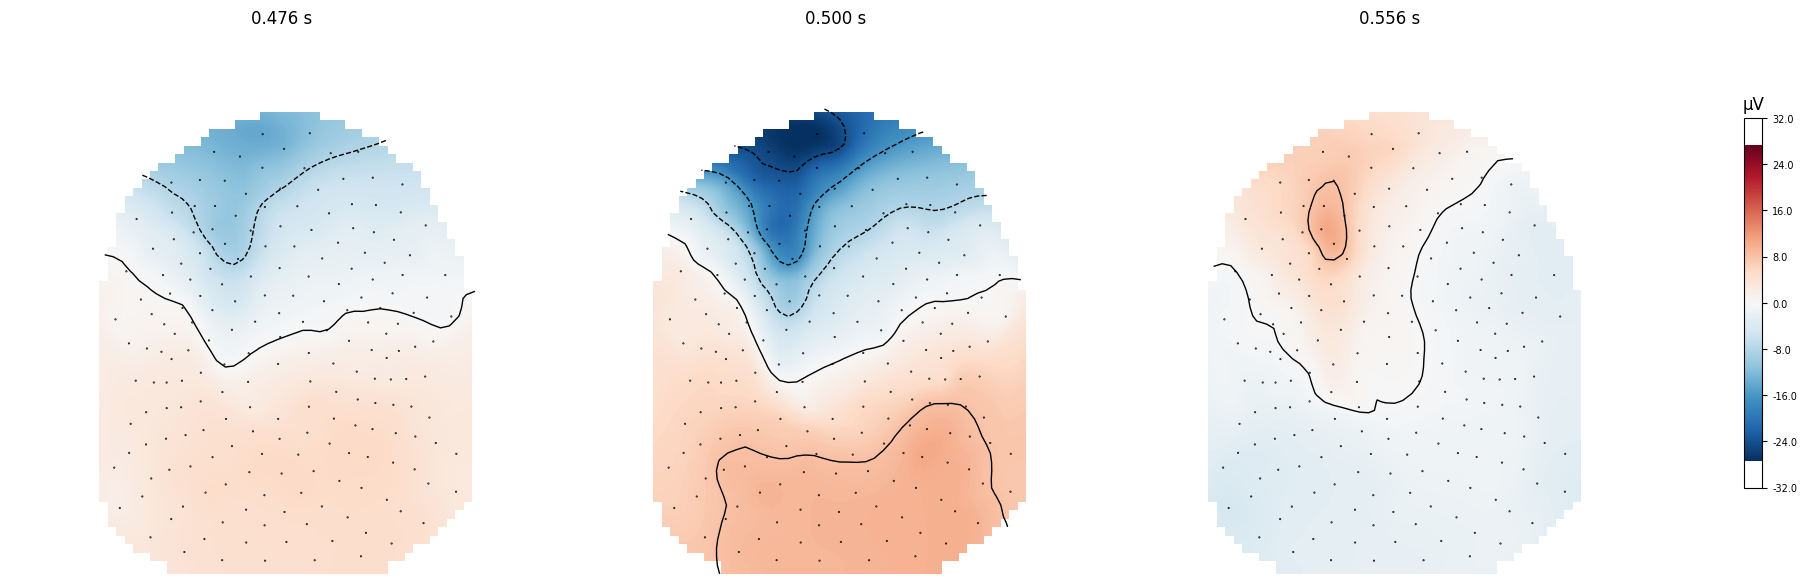

In [27]:
times = [hrp_time, peak_time, 0.556]
_ = data["eeg"].plot_topomap(times=times, size=4, extrapolate="local", outlines=None)

🛠️ <font color=violet>**Time window**</font>:
- `win_size`: time window around EEG peak in [s]

Number of samples: 27


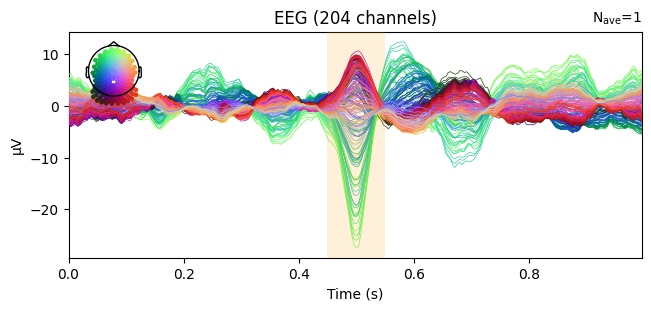

In [4]:
########### Parameters ###############
win_size = 0.1
######################################

if win_size:
    eeg = data["eeg"].copy()
    dt  = win_size/2
    eeg = eeg.crop(peak_time-dt, peak_time+dt)

    Y_ = eeg.data

    highlight = [peak_time-dt, peak_time+dt]

else:
    eeg = data["eeg"].copy()
    Y_  = eeg.data

    highlight = None

print(f"Number of samples: {Y_.shape[1]}")
_ = data["eeg"].plot(highlight=highlight)

## Compute CSET solution

#### ⚙️ <font color=green>**Apply CSET**</font>
Using the `pyxu` package we can write down any optimization problem and then solve them.

🛠️ <font color=violet>**CSET**</font> 
- `lam` ($\lambda$): regularizer parameter (influences the connectome spectrum sparsity)
- `dw`: depth weighting coefficient 

In [23]:
########### Parameters ###############
lam = 0.01
dw  = 1/2
######################################

# ----- Optimization problem -----
cst = data["cst"]

# standardize
Ynorms = np.linalg.norm(Y_, axis=0)
Y      = Y_/Ynorms[None,:]

L      = fwd - np.mean(fwd, axis=0)
Lnorms = np.linalg.norm(L, axis=0)**dw
L      = L / Lnorms[None,:] 

# component-wise transformation
L = L @ cst.T

# prior sparsity
prior = lam*pxo.L1Norm(dim_shape=cst.shape[0])

# initial guess
start = np.random.random(L.shape[1])*10**(-9)

# pyxu components
L     = pxa.LinOp.from_array(L)
prior = lam*pxo.L1Norm(dim_shape=cst.shape[0])
recon = np.random.rand(cst.shape[1], Y.shape[1])*10**-9
sc    = pxst.MaxIter(1000)


# ----- Optimization solving -----
for t in range(Y.shape[1]):
    y = Y[:,t]     # data time point

    likelihood = pxo.SquaredL2Norm(dim_shape=L.codim_shape).argshift(-y)*L
    likelihood.diff_lipschitz = likelihood.estimate_diff_lipschitz()

    solver = PGD(f=likelihood, g=prior, show_progress=False)

    solver.fit(x0=start, stop_crit=sc)

    alpha = solver.solution().squeeze()
    recon[:,t] = (1/Lnorms) * (cst.T @ alpha) * Ynorms[t]


# Store in MNE object
vertices = [data["fwd"]["src"][0]["vertno"], data["fwd"]["src"][1]["vertno"]]
stc      = mne.SourceEstimate(recon, vertices, tmin=eeg.times[0], tstep=1/eeg.info["sfreq"], subject=sub)

🌟 **Visualize reconstruction** <br>
🛠️ <font color=violet>**Time point**</font>
- `time`: time point to visualize (`hrp_time` or `peak_time`), if None then whole time serie is shown
- `show_gt`: show ground truth. Only possible for resection area so far

In [28]:
stc.tmin

np.float64(0.448)

In [29]:
################ Parameters #################
time    = None
show_gt = True
#############################################

if time:
    idx = stc.time_as_index(time)
    img = np.abs(stc.data[:,idx])
    
    if show_gt:
        mm.viz.plot_resection(data["fwd"]["src"], data["resec"], signal=img).show()
    else:
        mm.viz.plot_brain_signal(data["fwd"]["src"], img, cmap="reds", show_max=True).show()

else:
    img = np.abs(stc.data)
    img = img/np.max(img, axis=0)[None,:]
    mm.viz.plot_brain_time_series(
        data["fwd"]["src"], 
        img, 
        t_start = stc.tmin, 
        sfreq   = eeg.info["sfreq"], 
        cmap    = "reds"
    )

Widget(value='<iframe src="http://localhost:41199/index.html?ui=P_0x7a1015d10090_24&reconnect=auto" class="pyv…

#### 💾 **Save reconstruction**

In [ ]:
############### Parameters #################
overwrite = True
############################################

fname = mm_dir/sub/"inv"/f"{sub}-{samp}_cset-{lam}"

if not fname.parent.exists():
    fname.parent.mkdir(parents=True)

vertices = [data["fwd"]["src"][0]["vertno"], data["fwd"]["src"][1]["vertno"]]
stc = mne.SourceEstimate(recon, vertices, tmin=t_start, tstep=1/sfreq, subject=sub)
stc.save(fname, overwrite=overwrite)  
print(f"\033[92mSuccessfully saved CSET solution for subject '{sub}', sample '{samp}' with lam={lam}.")

Writing STC to disk...
Overwriting existing file.
Overwriting existing file.
[done]
Successfully saved CSET solution for subject 'sub-pat04', sample 'spike' with lam=0.1.


## Ground Truth
🌟 **Brain** <br>
🛠️ <font color=violet>**Time point**</font>
- `tp`: time point to visualize (`thalf` or `tpeak`), if None then whole time serie is shown

In [4]:
################ Parameters #################
tp = idx_half
#############################################

if "gt" in data.keys():
    if tp is None:
        mm.viz.plot_brain_time_series(data["fwd"]["src"], data["gt"].data, sfreq=sfreq)
    else:
        mm.viz.plot_brain_signal(data["fwd"]["src"], np.abs(data["gt"].data[:,tp]), cmap="reds").show()

else:
    plotter = mm.viz.plot_resection(data["fwd"]["src"], data["resec"], color="red")
    plotter.add_legend(face="circle")
    plotter.show()

NameError: name 'idx_half' is not defined

🌟 **Connectome Spectrum** <br>
🛠️ <font color=violet>**Time point**</font>
- `tp`: time point to visualize (`ht` or `pt`), if None then whole time serie is shown

In [7]:
################ Parameters #################
tp = ht
#############################################

if "gt" in data.keys():
    mm.viz.plot_spectrum(data["cst"]@data["gt"].data[:,ht]).show()

In [55]:
def plot_resection(
        sources, 
        resection, 
        cras=np.zeros(3), 
        signal=None, 
        show_max=False, 
        cmap="reds", 
        style="vox", 
        color="green"
):
    """
    Plot resection area. 

    Parameters
    ----------
    sources: mne.SourceSpaces
        Source space.

    resection: nib.Nifti1Image
        Resection mask.

    cras: np.ndarray (3,)
        Translation (FreeSurfer -> MRI)

    signal: np.ndarray (N,)
        Brain activity.

    show_max: bool
        Show maximum of brain acitivity.

    cmap: str
        Color map for brain activity.

    style: str
        Style of resection area:
        - cloud: looks like a cloud
        - vox: see individual voxels

    color: str
        Color of resection area. 
    """
    
    if signal is None:
        signal = np.zeros(sources[0]["nuse"]+sources[1]["nuse"])

    if style == "cloud":
        style = dict(
            emissive = True,
            style = "points_gaussian",
            point_size = 10,
        )
    elif style == "vox":
        style = dict(
            point_size=10,
            opacity=0.01,
        )
    else:
        raise ValueError(f"Unknown style '{style}' for resection plot.")

    # resection area
    voxels = np.argwhere(resection.get_fdata()>0)
    points = (nib.affines.apply_affine(resection.affine, voxels)-cras)/1000

     # plotter
    plotter = mm.viz.plot_brain_signal(sources, signal, cmap=cmap, show_max=show_max)
    plotter.add_mesh(pv.PolyData(points), color=color, label="Resected Area", **style)

    return plotter


plot_resection(data["fwd"]["src"], data["resec"], signal=np.abs(recon[:,idx_half]), color="pink").show()

Widget(value='<iframe src="http://localhost:46401/index.html?ui=P_0x7dde12d77410_32&reconnect=auto" class="pyv…

In [ ]:
data["resec"]